# Data assimilation in the reservoir: an echo state network without a washout

An echo state network (ESN) forecasts from its input, $\boldsymbol{u}$, and its reservoir, $\boldsymbol{r}$, which must be synchronized with the system first. The standard washout drives the network with the full state for many consecutive steps. Here, an ensemble filter estimates $\boldsymbol{\psi} = [\boldsymbol{u}; \boldsymbol{r}]$ from sparse and noisy data instead. The tutorial has three parts:

1. **Lorenz-63:** the deployment with the filter, against the washout and the substitution of the data;
2. **Partial observations:** the same system, with a component that is never measured;
3. **Lorenz-96:** ten sites on a ring, with inflation and sparse sensors.

The networks, data and filters are those of `scripts/esnda` (`configs/lorenz63.yml`, `configs/lorenz96_small.yml`). Tutorial 41 extends the deployment to parameter estimation; the plotting helpers are in `aux_4X.py`.

In [1]:
import numpy as np

from romda.models.physical import Lorenz63, Lorenz96
from romda.models.data_driven.rnns import model_esn
from romda.observations import Observations, measured_idx
from romda.estimators import EnSRKF
from romda.data_assimilation import as_result, deploy
from romda.metrics import state_metrics, valid_time
from romda.run import innovation_options
from romda.utils import interpolate
from aux_4X import (BLUE, GREEN, GREY, ORANGE, VERMILLION, config, plot_components, plot_dot_rows, plot_errors,
                   plot_members, plot_space_time, plot_sweep, plot_washout, valid_times, washout_forecasts)

## Part 1. Lorenz-63

### 1.1 The network and its washout

`model_esn` trains the ESN (100 units) on 100 Lyapunov times of the record with 5 % noise, or loads it from the store. The held-out end of the record is the truth. Forecasts after a washout on noise-free and on noisy data:

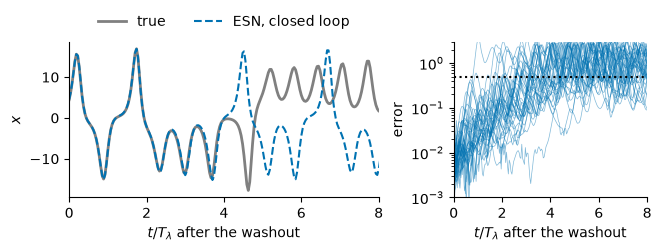

valid time after a washout on noise-free data: median 2.8 Lyapunov times


valid time after a washout on noisy data: median 1.7 Lyapunov times


In [2]:
CONFIG = config('lorenz63')
DA = CONFIG['da']

esn, data = model_esn(Lorenz63, CONFIG['truth'], CONFIG['forecast']['esn'])
t_lyap, N_lyap, i_test = data['t_lyap'], data['N_lyap'], data['i_test']
clean, noisy = data['clean_data'][i_test:], data['noisy_data'][i_test:]
t = data['t'][i_test:] - data['t'][i_test]

n_forecast, starts = 300, np.arange(40) * 4 * N_lyap
t_forecast = np.arange(n_forecast) * esn.dt_ESN / t_lyap
forecast, target, errors = washout_forecasts(esn, clean, clean, starts, n_forecast)
plot_washout(t_forecast, target, forecast, errors)
for label, record in [('noise-free', clean), ('noisy', noisy)]:
    vt = valid_times(washout_forecasts(esn, record, clean, starts, n_forecast)[2], t_forecast)
    print(f'valid time after a washout on {label} data: median {np.median(vt):.1f} Lyapunov times')

The washout consumes 20 consecutive snapshots of the full state, and the forecast is valid for 2.8 Lyapunov times (1.7 when the washout data are noisy).

### 1.2 Deployment with the ensemble filter

The EnSRKF updates $[\boldsymbol{u}; \boldsymbol{r}]$ of 20 networks every 0.19 Lyapunov times. The observation operator selects rows of $\boldsymbol{\psi}$, so no Jacobian of the network is needed. Choices, from the configuration:

- the members start from reservoir states visited in training, i.e. on the attractor of the network;
- $\boldsymbol{\mathsf{C}}_{dd}$ has 0.2 of the standard deviation of each observable, four times the data noise, because it also covers the error of the network;
- the innovation-based inflation.

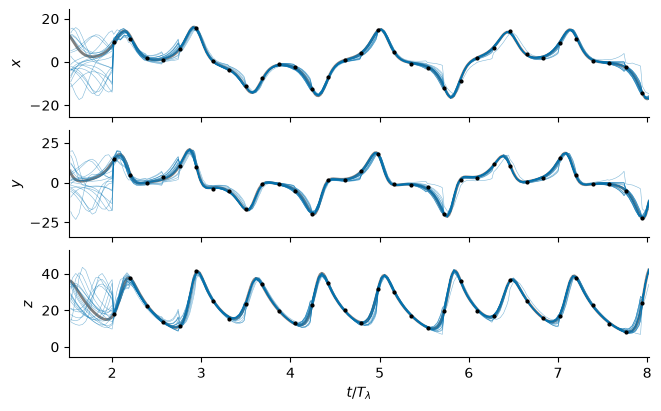

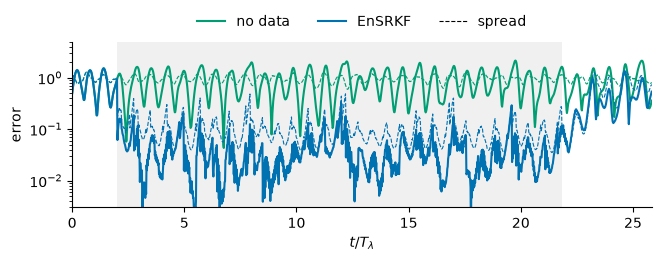

error 0.052, spread 0.116, valid time after the data 1.3 Lyapunov times


In [3]:
T_START, T_STOP, T_FORECAST = CONFIG['window_lyap']        # in Lyapunov times
FILTER = dict(m=DA['m'], da_method=DA['da_method'], cdd_fraction=DA['cdd_fraction'],
              inflation=DA['inflation'], **innovation_options(DA), t_extra=T_FORECAST * t_lyap)


def observe(Nt_obs=DA['Nt_obs'], window=0, measured=[0, 1, 2]):
    """Noisy observations of the `measured` components every `Nt_obs` steps; `window` moves the experiment by 4
    Lyapunov times."""
    return Observations(y_raw=noisy[:, measured], y_true=clean[:, measured], t_true=t, Nt_obs=Nt_obs,
                        t_start=(T_START + 4 * window) * t_lyap, t_stop=(T_STOP + 4 * window) * t_lyap)


truth = observe()
run = deploy(esn, truth, measured=[0, 1, 2], **FILTER)
free = EnSRKF(parent_model=esn, m=DA['m'], measured=[0, 1, 2])
free.forecast_step(t_end=truth.t_obs[-1] + T_FORECAST * t_lyap, close=True)

plot_members(run, truth, t, clean, t_lyap)
plot_errors({'no data': (as_result(free), GREEN), 'EnSRKF': (run, BLUE)}, truth, t, clean, t_lyap)
s = state_metrics(run, truth, t, clean, t_lyap=t_lyap)
print(f"error {s['rmse_mean_sync']:.3f}, spread {s['spread_sync']:.3f}, "
      f"valid time after the data {s['valid_time_mean_forecast']:.1f} Lyapunov times")

The filter synchronizes the network at the first analyses, with no washout, and keeps the error at the level of the data noise. The ensemble is over-dispersed (spread about twice the error) because of the large $\boldsymbol{\mathsf{C}}_{dd}$, so the inflation does not act.

### 1.3 Filter or substitution?

With every component observed, the data can also replace the input of the network at each observation time (`bayesian_update=False`). This corrects $\boldsymbol{u}$ only; the filter also corrects $\boldsymbol{r}$. Medians over ten windows:

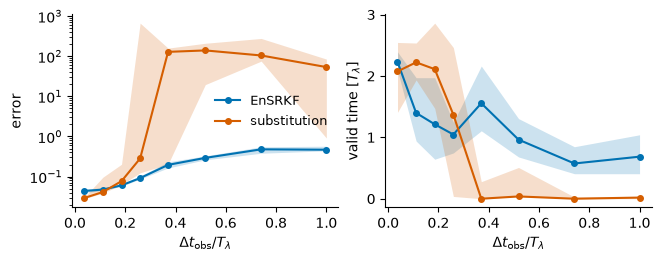

In [4]:
intervals = [2, 6, 10, 14, 20, 28, 40, 54]                 # Nt_obs, in steps of the record


def scores(run, truth):
    s = state_metrics(run, truth, t, clean, t_lyap=t_lyap)
    return s['rmse_mean_sync'], s['valid_time_mean_forecast']


sweep = np.zeros((2, len(intervals), 10, 2))
for i, Nt_obs in enumerate(intervals):
    for w in range(10):
        truth_w = observe(Nt_obs, window=w)
        sweep[0, i, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], **FILTER), truth_w)
        sweep[1, i, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], bayesian_update=False,
                                       open_loop_ensemble=True, m=DA['m'], t_extra=T_FORECAST * t_lyap), truth_w)
plot_sweep(np.array(intervals) * data['dt'] / t_lyap, {'EnSRKF': (sweep[0], BLUE), 'substitution': (sweep[1], VERMILLION)},
           r'$\Delta t_\mathrm{obs}/T_\lambda$', ['error', r'valid time [$T_\lambda$]'])

- Frequent data ($\Delta t_\mathrm{obs} \lesssim 0.2\,T_\lambda$): the substitution is as accurate as the filter. It is a washout spread over the data.
- Sparse data: the substitution fails from $0.37\,T_\lambda$, whereas the error of the filter stays bounded.

### 1.4 Estimating the readout

`est_alpha=['Wout']` appends the singular values of $\boldsymbol{\mathsf{W}}_\mathrm{out}$ to $\boldsymbol{\psi}$:

In [5]:
readout = np.zeros((2, 10, 2))
for w in range(10):
    truth_w = observe(window=w)
    readout[0, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], **FILTER), truth_w)
    readout[1, w] = scores(deploy(esn, truth_w, measured=[0, 1, 2], est_alpha=['Wout'], std_alpha=0.04, **FILTER), truth_w)
for label, r in zip(['state', 'state and readout'], readout):
    print(f'{label:<18} median error {np.median(r[:, 0]):.3f}, valid time {np.median(r[:, 1]):.2f}')

state              median error 0.060, valid time 1.21
state and readout  median error 0.064, valid time 1.31


No gain here: the readout of this network is already accurate. Tutorial 42 estimates the readout of a POD-ESN, where the training data are scarce.

## Part 2. Partial observations

The sensors measure $x$ and $z$ of the Lorenz-63 system; $y$ is never measured. Two networks, both with the full state as output:

- **partial-input:** the inputs are the measured components; it can be deployed with a washout, the substitution of the data, or the filter;
- **full-input:** the inputs are the full state, i.e. the network of Part 1; only the filter can deploy it, because $y$ is not available.

### 2.1 Four deployments

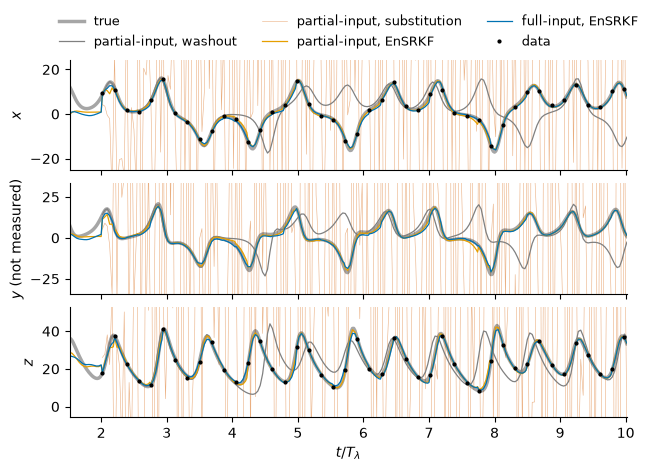

In [6]:
MEASURED, HIDDEN = [0, 2], [1]

esn_full, _ = model_esn(Lorenz63, CONFIG['truth'], CONFIG['forecast']['esn'])       # the network of Part 1, as stored
esn_partial, _ = model_esn(Lorenz63, CONFIG['truth'], CONFIG['forecast']['esn'], measured=MEASURED, bayesian_update=False)
sigma = clean.std(axis=0)


def component_errors(run, truth):
    """Error of each component (normalized by its standard deviation), and its root mean square after two Lyapunov
    times of data, over the three components and over y."""
    e = (run['y'] - interpolate(t, clean, run['t'])) / sigma
    w = (run['t'] >= truth.t_obs[0] + 2 * t_lyap) & (run['t'] <= truth.t_obs[-1])
    return e, np.sqrt(np.mean(e[w] ** 2)), np.sqrt(np.mean(e[w][:, HIDDEN] ** 2))


def washout_forecast(truth):
    """Partial-input network: washout on the measured components at every network step, then closed loop."""
    i0 = int(np.searchsorted(t, truth.t_obs[0]))
    n = int((truth.t_obs[-1] + T_FORECAST * t_lyap - truth.t_obs[0]) / esn_partial.dt_ESN)
    y, _ = esn_partial.closed_loop(noisy[i0 - esn_partial.N_wash * esn_partial.upsample::esn_partial.upsample], n)
    return dict(t=t[i0] + np.arange(n) * esn_partial.dt_ESN, y=y, ensemble=None)


def deployments(truth):
    return {'partial-input, washout': (washout_forecast(truth), GREY),
            'partial-input, substitution': (deploy(esn_partial, truth, measured=MEASURED, bayesian_update=False,
                                                   open_loop_ensemble=True, m=DA['m'], t_extra=T_FORECAST * t_lyap),
                                            VERMILLION),
            'partial-input, EnSRKF': (deploy(esn_partial, truth, **FILTER), ORANGE),
            'full-input, EnSRKF': (deploy(esn_full, truth, measured=MEASURED, **FILTER), BLUE)}


truth = observe(measured=MEASURED)
runs = deployments(truth)
plot_components(runs, truth, t, clean, t_lyap, MEASURED)

### 2.2 Ten windows

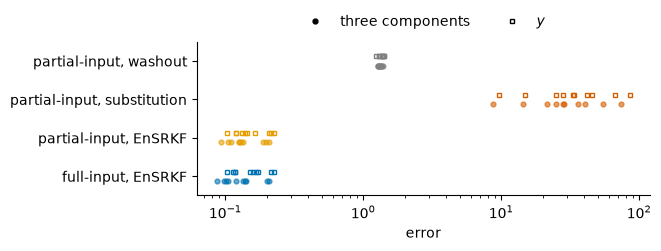

partial-input, washout         median error 1.308, of y 1.356
partial-input, substitution    median error 28.392, of y 33.431
partial-input, EnSRKF          median error 0.128, of y 0.141
full-input, EnSRKF             median error 0.127, of y 0.155
valid time of the washout forecast: median 2.0 Lyapunov times


In [7]:
table = np.array([[component_errors(run, truth_w)[1:] for run, _ in deployments(truth_w).values()]
                  for truth_w in (observe(measured=MEASURED, window=w) for w in range(10))]).transpose(1, 0, 2)
plot_dot_rows(table, list(runs), [c for _, c in runs.values()])
for label, row in zip(runs, np.median(table, axis=1)):
    print(f'{label:<30} median error {row[0]:.3f}, of y {row[1]:.3f}')
vt = [valid_time(np.sqrt(np.mean(component_errors(r, tr)[0] ** 2, axis=1)), r['t'] - r['t'][0]) / t_lyap
      for tr in (observe(measured=MEASURED, window=w) for w in range(10)) for r in [washout_forecast(tr)]]
print(f'valid time of the washout forecast: median {np.median(vt):.1f} Lyapunov times')

- The washout forecast is valid for about two Lyapunov times and then loses the state, because it gets no more data.
- The substitution fails: correcting the input alone does not synchronize the reservoir.
- Only the filters estimate the state, $y$ included, from the sparse data. The two networks reach the same error (median 0.13), but the full-input network serves every sensor layout, whereas the partial-input network must be trained for each layout.

### 2.3 Which components must be measured?

In [8]:
for measured in ([0, 2], [0], [1], [2]):
    e = [component_errors(deploy(esn_full, tr, measured=measured, **FILTER), tr)[1] for tr in (observe(measured=measured, window=w) for w in range(10))]
    print(f'{", ".join("xyz"[k] for k in measured):<6} median error {np.median(e):.3f}, failed windows {np.sum(np.array(e) > 1)}')

x, z   median error 0.127, failed windows 0


x      median error 0.158, failed windows 0


y      median error 0.102, failed windows 0


z      median error 406.856, failed windows 9


$x$ alone or $y$ alone suffice; $z$ alone does not. The Lorenz-63 system is invariant under $(x, y, z) \to (-x, -y, z)$, so $z$ does not determine the sign of $x$ and $y$, and the posterior is bimodal. Tutorial 17 introduces the Gaussian-mixture filter for this case.

## Part 3. Lorenz-96

The deployment of Part 1 on the Lorenz-96 system with ten sites on a ring,

$$
\frac{\mathrm{d}u_i}{\mathrm{d}t} = (u_{i+1} - u_{i-2})\,u_{i-1} - u_i + F, \qquad F = 8,
$$

which raises two questions: inflation, and sensors that are sparse in space.

### 3.1 The network

500 reservoir units, trained on 400 Lyapunov times with 2 % noise. Forecasts after a washout:

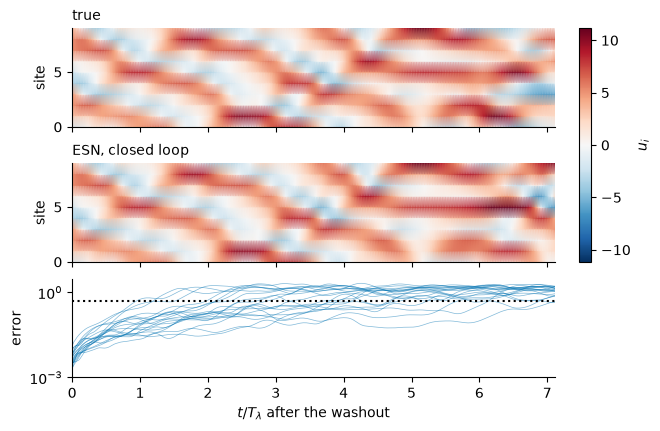

median valid time: 3.3 Lyapunov times


In [9]:
CONFIG = config('lorenz96_small')
DA = CONFIG['da']

esn, data = model_esn(Lorenz96, CONFIG['truth'], CONFIG['forecast']['esn'])
t_lyap, N_lyap, i_test = data['t_lyap'], data['N_lyap'], data['i_test']
clean, noisy = data['clean_data'][i_test:], data['noisy_data'][i_test:]
t = data['t'][i_test:] - data['t'][i_test]
N_sites = clean.shape[1]

t_forecast = np.arange(300) * esn.dt_ESN / t_lyap
forecast, target, errors = washout_forecasts(esn, clean, clean, np.arange(20) * 8 * N_lyap, 300)
plot_washout(t_forecast, target, forecast, errors, space=True)
print(f'median valid time: {np.median(valid_times(errors, t_forecast)):.1f} Lyapunov times')

### 3.2 Every site observed: is inflation needed?

EnSRKF with 64 members, observations every 0.1 Lyapunov times, with the innovation-based inflation and without:

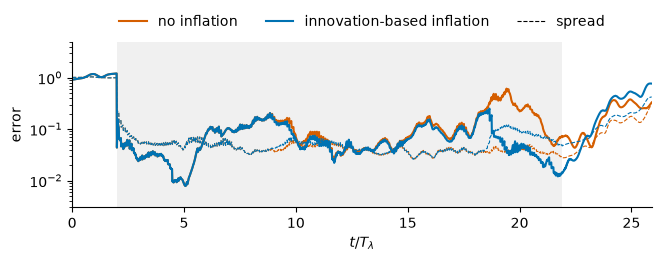

no inflation                 error 0.155, spread / error 0.28
innovation-based inflation   error 0.086, spread / error 0.65


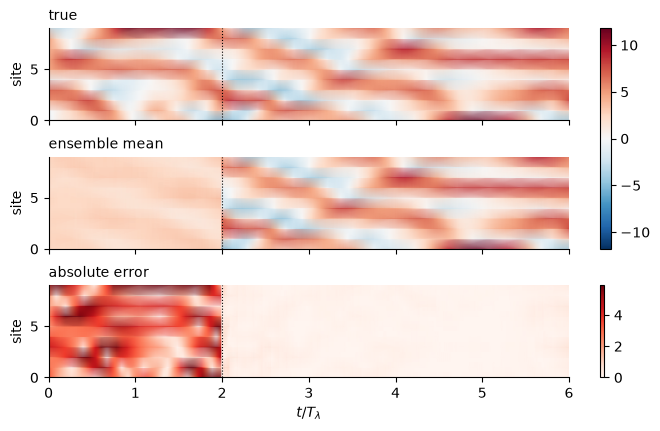

In [10]:
T_START, T_STOP, T_FORECAST = CONFIG['window_lyap']
FILTER = dict(m=DA['m'], da_method=DA['da_method'], cdd_fraction=DA['cdd_fraction'],
              **innovation_options(DA), t_extra=T_FORECAST * t_lyap)


def observe(n_sensors=N_sites, window=0):
    """Sensor sites (evenly spread on the ring) and their noisy observations."""
    sensors = measured_idx(n_sensors, N_sites, ring=True)
    return sensors, Observations(y_raw=noisy[:, sensors], y_true=clean[:, sensors], t_true=t, Nt_obs=DA['Nt_obs'],
                                 t_start=(T_START + 4 * window) * t_lyap, t_stop=(T_STOP + 4 * window) * t_lyap)


sensors, truth = observe()
run = deploy(esn, truth, measured=sensors, inflation='innovation', **FILTER)
run_1 = deploy(esn, truth, measured=sensors, inflation=1.0, **FILTER)
plot_errors({'no inflation': (run_1, VERMILLION), 'innovation-based inflation': (run, BLUE)}, truth, t, clean, t_lyap)
for label, r in [('no inflation', run_1), ('innovation-based inflation', run)]:
    s = state_metrics(r, truth, t, clean, t_lyap=t_lyap)
    print(f"{label:<28} error {s['rmse_mean_sync']:.3f}, spread / error {s['spread_skill']:.2f}")

w = run['t'] <= truth.t_obs[0] + 4 * t_lyap
u_true = clean[np.searchsorted(t, run['t'][w])]
plot_space_time({'true': u_true, 'ensemble mean': run['y'][w], 'absolute error': np.abs(run['y'][w] - u_true)},
                run['t'][w] / t_lyap, truth.t_obs[0] / t_lyap)

Without inflation, the ensemble is under-dispersed (spread about a quarter of the error) because of the model error of the network. The innovation-based inflation, 4 % on average, halves the error. On the Lorenz-63 system (Part 1), the same filter is over-dispersed and the inflation does not act: the factor must adapt to the case.

### 3.3 Sparse sensors

For the filter, only the observation operator changes. The substitution needs a network whose inputs are the measured sites, i.e. one network per sensor layout (`model_esn(..., measured=sensors, bayesian_update=False)`). Five windows each:

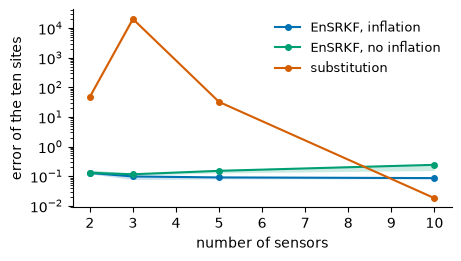

In [11]:
layouts = [10, 5, 3, 2]
sparse = np.zeros((3, len(layouts), 5, 1))
for i, n_sensors in enumerate(layouts):
    esn_sub, _ = model_esn(Lorenz96, CONFIG['truth'], CONFIG['forecast']['esn'],
                           measured=measured_idx(n_sensors, N_sites, ring=True), bayesian_update=False)
    for w in range(5):
        sensors, truth_w = observe(n_sensors, window=w)
        runs = [deploy(esn, truth_w, measured=sensors, inflation='innovation', **FILTER),
                deploy(esn, truth_w, measured=sensors, inflation=1.0, **FILTER),
                deploy(esn_sub, truth_w, measured=sensors, bayesian_update=False, t_extra=T_FORECAST * t_lyap)]
        sparse[:, i, w, 0] = [state_metrics(r, truth_w, t, clean, t_lyap=t_lyap)['rmse_mean_sync'] for r in runs]
plot_sweep(layouts, {'EnSRKF, inflation': (sparse[0], BLUE), 'EnSRKF, no inflation': (sparse[1], GREEN),
                     'substitution': (sparse[2], VERMILLION)}, 'number of sensors', ['error of the ten sites'])

- The substitution is the most accurate with every site measured, and fails with five sensors or fewer.
- The filter reconstructs the ten sites from two sensors with one network (median error 0.09 to 0.13).
- Inflation matters when the sensors are dense, which is when the ensemble is under-dispersed.

The 40-site system, with a localized filter, is in `scripts/esnda/run/run_parallel_localization.py`.